<a href="https://colab.research.google.com/github/Areeha548/Logistic-Regression-from-Scratch-/blob/main/logistic_regression_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Build Your Own Logistic Regression### CS535 / EE514 · Assignment · ≈ 2 hoursWelcome. In the last lecture we built logistic regression on paper. Today you are going to build it in code — from scratch, in NumPy — and run it on a real medical dataset.**The problem.** You have 30 measurements taken from a tumor biopsy (cell radius, texture, perimeter, concavity, and so on). From those numbers, your classifier must decide: is the tumor **malignant** (cancer) or **benign** (safe)?A doctor would use many signals to decide. Your job is to teach a logistic regression model to do the same, using only linear algebra and gradient descent.### What you will build1. A `LogisticRegression` class with `fit`, `predict_proba`, and `predict` methods2. A training loop using batch gradient descent3. A loss curve, a decision boundary plot, and a confusion matrix4. A short discussion of threshold tuning in a medical setting### Rules of engagement- Use only **NumPy**, **Matplotlib**, and (for data loading / comparison) **scikit-learn**- Do **not** use `sklearn.linear_model.LogisticRegression` to build your model — only to compare at the end- Keep your code readable: this is as much about understanding as about correctnessLet's go.

---## 1. SetupStandard imports. Nothing to do here — just run the cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

np.random.seed(42)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

---## 2. Meet the dataThe dataset is the **Wisconsin Breast Cancer** dataset — 569 tumor biopsies, each described by 30 real-valued features (mean / standard error / "worst" of radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension). Each biopsy is labeled 0 (**malignant**) or 1 (**benign**).> ⚠️ Note on label convention: sklearn flips the intuitive convention — in this dataset, **1 = benign** and **0 = malignant**. We'll keep sklearn's convention throughout.

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

print(f"Features shape: {X.shape}")
print(f"Labels shape:   {y.shape}")
print(f"Class names:    {data.target_names}  (0 = malignant, 1 = benign)")
print(f"Class balance:  {np.bincount(y)}  →  {np.bincount(y) / len(y)}")

Features shape: (569, 30)
Labels shape:   (569,)
Class names:    ['malignant' 'benign']  (0 = malignant, 1 = benign)
Class balance:  [212 357]  →  [0.37258348 0.62741652]


### 2.1 A first look**TASK:** Pick any **two features** that you think are meaningful (for example `mean radius` and `mean texture`), and make a scatter plot colored by class. This gives you a feel for whether the classes are even linearly separable.The feature names live in `data.feature_names`.

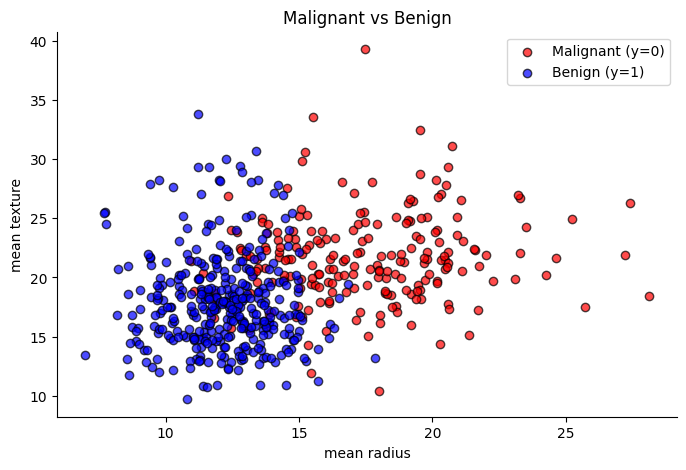

In [3]:
# TODO: Choose two feature indices and plot the data colored by class.
# Hint: use feat_a_idx and feat_b_idx; the names are in data.feature_names.

feat_a_idx = 0  # e.g. 0 for 'mean radius'
feat_b_idx = 1  # e.g. 1 for 'mean texture'

# Make the scatter plot: malignant (y=0) in one color, benign (y=1) in another.
# Label the axes using data.feature_names[idx], and add a legend.
# YOUR CODE HERE
plt.scatter(X[y == 0, feat_a_idx], X[y == 0, feat_b_idx],
            c="red", edgecolor="k", alpha=0.7, label="Malignant (y=0)")
plt.scatter(X[y == 1, feat_a_idx], X[y == 1, feat_b_idx],
            c="blue", edgecolor="k", alpha=0.7, label="Benign (y=1)")
plt.xlabel(data.feature_names[feat_a_idx])
plt.ylabel(data.feature_names[feat_b_idx])
plt.title("Malignant vs Benign")
plt.legend()
plt.show()


---## 3. PreprocessingLogistic regression is sensitive to feature scale: a feature that ranges from 0 to 1000 will dominate one that ranges from 0 to 1, no matter which is more informative. We fix this by **standardizing** each feature to have mean 0 and standard deviation 1.**TASK:** Split the data into train/test (80/20) and standardize the features. Fit the scaler on the training set only, then apply it to both train and test (otherwise you leak information).

In [4]:
# TODO: train_test_split with test_size=0.2, random_state=42, stratify=y
# TODO: fit StandardScaler on X_train only, transform both

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)  # YOUR CODE HERE

scaler = StandardScaler().fit(X_train)  # YOUR CODE HERE
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape}, Test: {X_test_scaled.shape}")
print(f"Train mean (should be ~0): {X_train_scaled.mean():.4f}")
print(f"Train std  (should be ~1): {X_train_scaled.std():.4f}")

Train: (455, 30), Test: (114, 30)
Train mean (should be ~0): -0.0000
Train std  (should be ~1): 1.0000


---## 4. Build your `LogisticRegression` classThis is the heart of the assignment. You will implement five short methods. Each one is a direct translation of something from the lecture.### What the pieces are| Method | What it does | The math ||---|---|---|| `_sigmoid(z)` | squashes a real number into (0, 1) | σ(z) = 1 / (1 + exp(−z)) || `_cost(y_true, y_pred)` | cross-entropy loss | − mean( y·log(h) + (1−y)·log(1−h) ) || `_gradient(X, y_true, y_pred)` | ∂cost/∂θ, averaged over the batch | (1/m) · Xᵀ (h − y) || `fit(X, y)` | gradient descent loop | θ ← θ − α · ∇cost || `predict_proba(X)` / `predict(X)` | run the trained model | σ(Xθ + b), then threshold |### Why we add a tiny `eps`In `_cost`, if the model predicts exactly 0 or exactly 1, you'll compute `log(0) = -inf` and training explodes. Clip the predictions into `[eps, 1 − eps]` first.

In [5]:
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000, verbose=False):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.verbose = verbose
        self.weights = None     # θ, shape (n_features,)
        self.bias = None        # b, scalar
        self.loss_history = []  # one entry per iteration

    # ------------------------------------------------------------
    def _sigmoid(self, z):
        """Return 1 / (1 + exp(-z)). Vectorized over arrays."""
        # TODO: implement
        # Hint: use np.exp. One line.
        # YOUR CODE HERE
        return 1 / (1 + np.exp(-z))

    # ------------------------------------------------------------
    def _cost(self, y_true, y_pred):
        """Binary cross-entropy loss, averaged over the batch.
        Clip y_pred to [eps, 1-eps] to avoid log(0)."""
        eps = 1e-15
        # TODO: implement
        # Hint: clip y_pred first, then return the mean of
        #       -( y*log(h) + (1-y)*log(1-h) )
        # YOUR CODE HERE
        y_pred = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    # ------------------------------------------------------------
    def _gradient(self, X, y_true, y_pred):
        """Return (dW, db): gradient of cost w.r.t. weights and bias.
        X has shape (m, n). y_true, y_pred have shape (m,)."""
        m = X.shape[0]
        error = y_pred - y_true  # shape (m,)
        # TODO: implement
        # dW: (1/m) * X.T @ error      → shape (n,)
        # db: (1/m) * sum(error)       → scalar
        # YOUR CODE HERE
        dW = (1 / m) * X.T @ error
        db = (1 / m) * np.sum(error)
        return dW, db

    # ------------------------------------------------------------
    def fit(self, X, y):
        """Gradient descent loop. Updates self.weights, self.bias,
        and appends to self.loss_history each iteration."""
        m, n = X.shape
        self.weights = np.zeros(n)
        self.bias = 0.0
        self.loss_history = []

        for i in range(self.n_iterations):
            # 1. Forward pass: compute z, then y_pred
            # 2. Compute loss and append to self.loss_history
            # 3. Compute gradients
            # 4. Update self.weights and self.bias
            # YOUR CODE HERE
            z = X @ self.weights + self.bias
            y_pred = self._sigmoid(z)
            self.loss_history.append(self._cost(y, y_pred))
            dW, db = self._gradient(X, y, y_pred)
            self.weights -= self.learning_rate * dW
            self.bias -= self.learning_rate * db

            if self.verbose and i % 100 == 0:
                print(f"Iter {i:4d}  |  loss = {self.loss_history[-1]:.4f}")

        return self

    # ------------------------------------------------------------
    def predict_proba(self, X):
        """Return probability of class 1 for each row of X."""
        # TODO: implement (one line of math)
        # YOUR CODE HERE
        return self._sigmoid(X @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        """Return the hard class label (0 or 1) for each row of X."""
        # TODO: implement
        # YOUR CODE HERE
        return (self.predict_proba(X) >= threshold).astype(int)

In [6]:
model = LogisticRegression(learning_rate=0.1, n_iterations=1000, verbose=True)
model.fit(X_train_scaled, y_train)

print("Final loss:", model.loss_history[-1])
print("Test accuracy:", (model.predict(X_test_scaled) == y_test).mean())

Iter    0  |  loss = 0.6931
Iter  100  |  loss = 0.0983
Iter  200  |  loss = 0.0801
Iter  300  |  loss = 0.0722
Iter  400  |  loss = 0.0676
Iter  500  |  loss = 0.0645
Iter  600  |  loss = 0.0621
Iter  700  |  loss = 0.0603
Iter  800  |  loss = 0.0589
Iter  900  |  loss = 0.0576
Final loss: 0.05661169022874778
Test accuracy: 0.9736842105263158


---## 5. Train the model**TASK:** Instantiate your `LogisticRegression` with `learning_rate=0.1`, `n_iterations=1000`, `verbose=True`, and call `fit` on the scaled training data.

In [7]:
# TODO: instantiate and fit
model = LogisticRegression(learning_rate=0.1, n_iterations=1000, verbose=True)  # YOUR CODE HERE
model.fit(X_train_scaled, y_train)  # YOUR CODE HERE

Iter    0  |  loss = 0.6931
Iter  100  |  loss = 0.0983
Iter  200  |  loss = 0.0801
Iter  300  |  loss = 0.0722
Iter  400  |  loss = 0.0676
Iter  500  |  loss = 0.0645
Iter  600  |  loss = 0.0621
Iter  700  |  loss = 0.0603
Iter  800  |  loss = 0.0589
Iter  900  |  loss = 0.0576


### 5.1 Plot the loss curveA healthy training curve starts high and decreases monotonically, flattening out at the end. A curve that oscillates wildly means your learning rate is too high; one that barely moves means it's too low.**TASK:** Plot `model.loss_history` versus iteration.

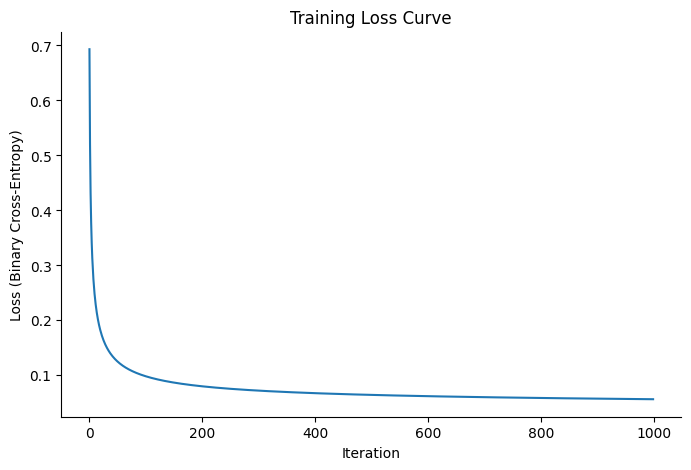

In [8]:
# TODO: plot the loss history
# YOUR CODE HERE
plt.plot(model.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Loss (Binary Cross-Entropy)")
plt.title("Training Loss Curve")
plt.show()

---## 6. Evaluate**TASK:** Compute **accuracy**, **precision**, and **recall** on the test set, and print a confusion matrix.Reminders:- **Precision** = of the tumors you called malignant, what fraction actually were?- **Recall** = of the actually malignant tumors, what fraction did you catch?Because `0 = malignant` here, we want **high recall for class 0** — missing a cancer is worse than a false alarm.

In [9]:
# TODO: get predictions on X_test_scaled, then compute metrics
y_pred = model.predict(X_test_scaled)  # YOUR CODE HERE

accuracy  = accuracy_score(y_test, y_pred)
# For precision/recall of the MALIGNANT class (label 0), pass pos_label=0
precision = precision_score(y_test, y_pred, pos_label=0)
recall    = recall_score(y_test, y_pred, pos_label=0)
cm        = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(f"Accuracy:                   {accuracy:.4f}")
print(f"Precision (malignant class): {precision:.4f}")
print(f"Recall    (malignant class): {recall:.4f}")
print(f"\nConfusion matrix (rows=true, cols=pred, order [malignant, benign]):")
print(cm)

Accuracy:                   0.9737
Precision (malignant class): 0.9535
Recall    (malignant class): 0.9762

Confusion matrix (rows=true, cols=pred, order [malignant, benign]):
[[41  1]
 [ 2 70]]


---## 7. Visualize the decision boundaryTo actually *see* the model, we need to project it into two dimensions. Train a **second** `LogisticRegression` using only the two features you picked in Section 2.1, and plot the decision boundary over the data.**TASK:** Train on just those two columns (standardized), then plot the probability as a background heatmap with the data points on top. The 0.5 contour is the decision boundary.

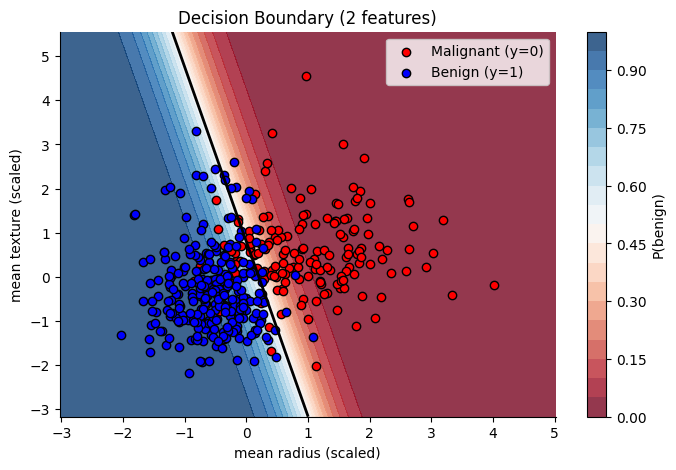

In [10]:
# Build a 2-feature dataset from the two indices you chose
X_2d = X_train_scaled[:, [feat_a_idx, feat_b_idx]]

# TODO: Train a new LogisticRegression on this 2D data
model_2d = LogisticRegression(learning_rate=0.1, n_iterations=1000).fit(X_2d, y_train)  # YOUR CODE HERE

# Plot: use np.meshgrid over a padded range of each feature,
# call model_2d.predict_proba on the grid, and use plt.contourf.
# Overlay the training points colored by y_train.
# YOUR CODE HERE
a_min, a_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
b_min, b_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(a_min, a_max, 300),
                     np.linspace(b_min, b_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = model_2d.predict_proba(grid).reshape(xx.shape)

plt.contourf(xx, yy, probs, levels=20, cmap="RdBu", alpha=0.8)   # probability heatmap
plt.colorbar(label="P(benign)")
plt.contour(xx, yy, probs, levels=[0.5], colors="k", linewidths=2)  # decision boundary

plt.scatter(X_2d[y_train == 0, 0], X_2d[y_train == 0, 1],
            c="red", edgecolor="k", label="Malignant (y=0)")
plt.scatter(X_2d[y_train == 1, 0], X_2d[y_train == 1, 1],
            c="blue", edgecolor="k", label="Benign (y=1)")
plt.xlabel(data.feature_names[feat_a_idx] + " (scaled)")
plt.ylabel(data.feature_names[feat_b_idx] + " (scaled)")
plt.title("Decision Boundary (2 features)")
plt.legend()
plt.show()

---## 8. The medical threshold questionBy default we classify using a 0.5 threshold. But in medicine, **missing a cancer (false negative) is much worse than a false alarm (false positive)**. A false alarm leads to another test; a missed cancer can be fatal.Because `0 = malignant` here, lowering the threshold below 0.5 means we only call a tumor benign if we are *very* sure it's benign — otherwise we flag it as malignant. That raises the recall of the malignant class.**TASK:** For each threshold in `[0.3, 0.4, 0.5, 0.6, 0.7]`, compute the recall and precision of the malignant class (label 0), and print a small table.

In [11]:
# TODO: Use the trained full-feature model (from Section 5).
y_proba = model.predict_proba(X_test_scaled)

print(f"{'threshold':>10} | {'recall(malig)':>13} | {'precision(malig)':>16}")
print("-" * 48)

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7 ,0.8,0.9]:
    # TODO: Build hard predictions, then compute recall and precision for pos_label=0
    # YOUR CODE HERE
    y_pred_t = (y_proba >= threshold).astype(int)
    rec = recall_score(y_test, y_pred_t, pos_label=0)
    prec = precision_score(y_test, y_pred_t, pos_label=0)
    print(f"{threshold:>10.1f} | {rec:>13.4f} | {prec:>16.4f}")

 threshold | recall(malig) | precision(malig)
------------------------------------------------
       0.3 |        0.9524 |           1.0000
       0.4 |        0.9524 |           0.9756
       0.5 |        0.9762 |           0.9535
       0.6 |        0.9762 |           0.8913
       0.7 |        0.9762 |           0.8913
       0.8 |        0.9762 |           0.8367
       0.9 |        1.0000 |           0.7636


**Reflect for a moment (no code):** Which threshold would you deploy at a hospital? Why? Write a two-sentence answer in the next cell.

I would deploy a high threshold, around 0.9 on the benign probability, because missing a cancer is far more dangerous than ordering an extra test for a false alarm. The cost is lower precision (about 76% in our test), so I would first check this choice on more data before using it with real patients.

---## 9. Sanity check: compare to scikit-learnFinally, let's see how your implementation stacks up against the reference. If you got it right, your accuracy should be within a percent or two of sklearn's.**TASK:** Train an `sklearn.linear_model.LogisticRegression` on the same scaled training data, and print its test accuracy. Then print yours again, side by side.

In [12]:
from sklearn.linear_model import LogisticRegression as SklearnLR

# TODO: fit sklearn's model and compare
# YOUR CODE HERE
sk_model = SklearnLR(max_iter=1000)
sk_model.fit(X_train_scaled, y_train)

sk_acc = accuracy_score(y_test, sk_model.predict(X_test_scaled))
my_acc = accuracy_score(y_test, model.predict(X_test_scaled))

print(f"{'Model':<22}| Test accuracy")
print("-" * 38)
print(f"{'My LogisticRegression':<22}| {my_acc:.4f}")
print(f"{'sklearn':<22}| {sk_acc:.4f}")
print(f"Difference: {abs(sk_acc - my_acc):.4f}")

Model                 | Test accuracy
--------------------------------------
My LogisticRegression | 0.9737
sklearn               | 0.9825
Difference: 0.0088


---## 10. What you builtIn roughly two hours you have:- Loaded a real medical dataset and inspected it visually- Standardized the features (and understood *why*)- Written a `LogisticRegression` class from scratch using nothing but NumPy- Trained it with gradient descent and watched the loss curve descend- Evaluated it with the right metrics for a medical problem (recall, not just accuracy)- Visualized the decision boundary in 2D- Tuned the threshold for the real-world cost of a mistake- Matched the accuracy of a professional libraryNot bad for an afternoon.### Stretch goals (optional)1. **Add L2 regularization.** Modify `_cost` and `_gradient` to penalize `λ · ‖θ‖²`. Does it help on the test set?2. **Mini-batch gradient descent.** Instead of using the whole training set every step, sample a batch of 32 examples per step. Plot the loss curve — it should be noisier but faster.3. **Try the 2D model with different feature pairs.** Which pair gives the cleanest decision boundary? Which gives the ugliest? Why?Submit the notebook with all cells run.

## 10. What I built

In this assignment I built logistic regression from scratch using only NumPy and tested it on the breast cancer dataset. Here is what I did in each part:

- **Section 1 (Setup):** I imported the libraries and loaded the breast cancer dataset (569 patients, 30 features).
- **Section 2.1 (A first look):** I made a scatter plot of two features (mean radius and mean texture), colored by class. The classes looked mostly separable with a straight line.
- **Section 3 (Preprocessing):** I split the data 80/20 and standardized the features. The scaler was fitted on the training set only, so no information leaked from the test set.
- **Section 4 (LogisticRegression class):** I wrote my own class with sigmoid, cost, gradient, fit, predict_proba and predict.
- **Section 5 (Train the model):** I trained the model with gradient descent for 1000 iterations with a learning rate of 0.1.
- **Section 5.1 (Loss curve):** I plotted the loss history. The loss went down from 0.693 to about 0.057, which shows the model was learning.
- **Section 6 (Evaluate):** On the test set the model got 97.4% accuracy and 97.6% recall for the malignant class. Only 1 cancer case was missed.
- **Section 7 (Decision boundary):** I trained a second model on 2 features and plotted the boundary. It is a straight line, as expected for logistic regression.
- **Section 8 (Medical threshold):** I tried different thresholds. A higher threshold on the benign probability catches more cancers, but it gives more false alarms. In my reflection I chose a high threshold because missing a cancer is worse.
- **Section 9 (Compare with scikit-learn):** My model got 97.4% and scikit-learn got 98.2%, so the difference is less than 1%.

I did not attempt the optional stretch goals.